# Week 42, Monday: from backpropagation to differential equations

This notebook contains the code behind every figure and number in the Monday lecture (`week42monday.pdf`). The sections follow the slides:

1. **Backpropagation**: the four equations in code, checked against `jax.grad`
2. **Activation functions and initialisation**
3. **Output activation and cost function**: why they come in pairs
4. **Universal approximation**: ReLU units are kinks
5. **Neural networks for differential equations**: the equation as the cost, activation functions, boundary conditions, soft constraints (PINNs) and an inverse problem

Run the cells from top to bottom. The slide figures (`figures/*.png`) are made by this notebook: set `SAVE_FIGURES = True` in the first code cell to regenerate them. The networks in Sections 1–4 are written in `numpy` (training on MNIST takes about a minute); `jax` checks the gradients in Section 1 and computes the derivatives in Section 5.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)     # double precision, so that gradient checks agree to ~1e-15
import jax.numpy as jnp

BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
plt.rcParams.update({"font.size": 14, "axes.titlesize": 14, "axes.labelsize": 14, "legend.fontsize": 12,
                     "xtick.labelsize": 12, "ytick.labelsize": 12})
np.set_printoptions(precision=4, suppress=True)

SAVE_FIGURES = False          # True: also write the slide figures to figures/*.png


def show(fig, name):
    if SAVE_FIGURES:
        fig.savefig(os.path.join("figures", name), dpi=200, bbox_inches="tight")
    plt.show()

## 1. Backpropagation

For one sample, with $z^l = W^l a^{l-1} + b^l$, $a^l = f(z^l)$ in the hidden layers and $a^L = f_L(z^L)$ in the output layer, the lecture derived the four equations

$$
\delta^L = f_L'(z^L)\circ\frac{\partial C}{\partial a^L},\qquad
\delta^l = \big((W^{l+1})^T\delta^{l+1}\big)\circ f'(z^l),\qquad
\frac{\partial C}{\partial b^l} = \delta^l,\qquad
\frac{\partial C}{\partial W^l} = \delta^l\,(a^{l-1})^T .
$$

The key step is the second equation. Node $j$ in layer $l$ feeds every node in layer $l+1$, so the chain rule sums over all these paths: $\delta^l_j = \sum_k \delta^{l+1}_k\, w^{l+1}_{kj}\, f'(z^l_j)$. Each $\delta^l$ reuses $\delta^{l+1}$, so the whole gradient costs about as much as one extra forward pass.

**In code we process many samples at once**, stacked as the *rows* of a matrix: $Z^l = A^{l-1}W^l + b^l$, with $W^l$ of shape (inputs, outputs). These are the same equations, transposed:

$$
\Delta^l = \big(\Delta^{l+1}(W^{l+1})^T\big)\circ f'(Z^l),\qquad
\frac{\partial C}{\partial W^l} = (A^{l-1})^T\Delta^l,\qquad
\frac{\partial C}{\partial b^l} = \sum_{\text{rows}}\Delta^l .
$$

The output layer uses one of three *output activations*, each with its own cost (Section 3). For all three pairs the backward pass starts with the same line, $\Delta^L = (A^L - Y)/n$.

In [2]:
def sigmoid(z):
    e = np.exp(-np.abs(z))                       # written so that it never overflows
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def softmax(z):
    e = np.exp(z - np.max(z, axis=1, keepdims=True))   # subtract the max: avoids overflow, same result
    return e / np.sum(e, axis=1, keepdims=True)


def relu(z):
    return np.maximum(0.0, z)


# hidden activations: (f, f')
ACTIVATIONS = {"sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
               "tanh": (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
               "relu": (relu, lambda z: (z > 0).astype(float)),
               "identity": (lambda z: z, lambda z: np.ones_like(z))}

# output activations, one for each cost function
OUTPUT = {"mse": lambda z: z, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    # A list of (W, b) pairs; sizes = [784, 100, 10] gives 784 -> 100 -> 10.
    # Weights with variance 2/M for ReLU and 1/M otherwise (M = inputs per node), see Section 2.
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        layers.append((rng.normal(0.0, scale, (n_in, n_out)), np.zeros(n_out) + 0.01))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    # Returns all z^l and a^l: the backward pass needs them.
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        z.append(a[-1] @ W + b)
        a.append(OUTPUT[head](z[-1]) if l == len(layers) - 1 else f(z[-1]))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse"):
    out = predict(X, layers, hidden_activation, head)
    if head == "mse":
        return 0.5 * np.sum((out - Y) ** 2) / len(X)
    p = np.clip(out, 1e-12, 1 - 1e-12)
    if head == "binary":
        return -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    return -np.mean(np.sum(Y * np.log(p), axis=1))


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse"):
    # The four equations, for all samples at once. Returns [(dW, db), ...] with the shapes of [(W, b), ...].
    _, fp = ACTIVATIONS[hidden_activation]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / len(X)                         # output layer: prediction minus target
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        grads[l] = (a[l].T @ delta, np.sum(delta, axis=0))   # dC/dW = A^T Delta,  dC/db = sum of rows
        if l > 0:
            W = layers[l][0]
            delta = (delta @ W.T) * fp(z[l - 1])         # one layer back
    return grads


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, rng=None, X_test=None, y_test=None):
    # Plain gradient descent on minibatches (batch_size=None: all data in every step).
    rng = np.random.default_rng(2026) if rng is None else rng
    n = len(X)
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head))
        if X_test is not None:
            pred = np.argmax(predict(X_test, layers, hidden_activation, head), axis=1)
            history["test_accuracy"].append(np.mean(pred == y_test))
    return layers, history


def one_hot(y, n_classes):
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y

### Always check your gradient

A hand-written backward pass must be checked. Here we compare `backpropagation` with `jax.grad` of the same cost, for all three output heads. The output layer of `backpropagation` always starts with $\Delta^L = (A^L - Y)/n$. If the agreement below is at the level of rounding errors ($10^{-16}$), this confirms that **prediction minus target** is the correct output error for all three pairs.

In [3]:
JAX_HIDDEN = {"sigmoid": jax.nn.sigmoid, "tanh": jnp.tanh, "relu": jax.nn.relu}
JAX_OUTPUT = {"mse": lambda z: z, "binary": jax.nn.sigmoid, "softmax": lambda z: jax.nn.softmax(z, axis=1)}


def cost_jax(layers, X, Y, hidden_activation, head):
    # The same network and cost as above, written with jax.numpy so that jax.grad can differentiate it.
    a = X
    for l, (W, b) in enumerate(layers):
        z = a @ W + b
        a = JAX_OUTPUT[head](z) if l == len(layers) - 1 else JAX_HIDDEN[hidden_activation](z)
    if head == "mse":
        return 0.5 * jnp.sum((a - Y) ** 2) / len(X)
    if head == "binary":
        return -jnp.mean(Y * jnp.log(a) + (1 - Y) * jnp.log(1 - a))
    return -jnp.mean(jnp.sum(Y * jnp.log(a), axis=1))


def to_jax(layers):
    return [(jnp.asarray(W), jnp.asarray(b)) for W, b in layers]


rng = np.random.default_rng(1)
X = rng.normal(size=(8, 3))
for head, n_out, Y in (("mse", 2, rng.normal(size=(8, 2))),
                       ("binary", 1, rng.integers(0, 2, (8, 1)).astype(float)),
                       ("softmax", 3, one_hot(rng.integers(0, 3, 8), 3))):
    layers = create_layers([3, 5, 4, n_out], "tanh", rng)
    mine = backpropagation(X, Y, layers, "tanh", head)
    ref = jax.grad(cost_jax)(to_jax(layers), X, Y, "tanh", head)
    err = max(float(np.max(np.abs(np.asarray(g_ref) - g_mine)))
              for (dW, db), (rW, rb) in zip(mine, ref) for g_mine, g_ref in ((dW, rW), (db, rb)))
    print(f"{head:8s} max |backpropagation - jax.grad| = {err:.1e}")

mse      max |backpropagation - jax.grad| = 1.1e-16
binary   max |backpropagation - jax.grad| = 2.8e-17
softmax  max |backpropagation - jax.grad| = 4.2e-17


### Why not start at zero?

**Think first.** A network starts with *all* weights and biases equal to zero. Using the four equations: which gradients are non-zero after the first backward pass? What happens after that?

*Answer:* only the output layer. $W^{l+1}=0$ gives $\delta^l = \big((W^{l+1})^T\delta^{l+1}\big)\circ f'(z^l) = 0$ in every hidden layer, whatever $f$ is, so no hidden weight or bias moves. Learning has to creep backwards from the output, one layer per step, and every gradient is a product of near-zero weights: slow to start at best. If $f(0)=0$, as for tanh, it never starts. Every hidden $a^l=0$, so even the output weights get $\partial C/\partial W^L = \delta^L(a^{L-1})^T = 0$; only the output bias moves, and the network can only learn a constant. On top of this comes **symmetry**: all units in a layer start identical, so they get identical gradients and stay copies of each other. The same happens for any equal non-zero start. Random weights break the symmetry. The cell below checks the answer for a tanh network with `backpropagation`.

In [4]:
rng = np.random.default_rng(4)
X_zero, Y_zero = rng.normal(size=(20, 3)), rng.normal(size=(20, 1))
layers_zero = [(np.zeros_like(W), np.zeros_like(b)) for W, b in create_layers([3, 5, 5, 1], "tanh")]
for l, (dW, db) in enumerate(backpropagation(X_zero, Y_zero, layers_zero, "tanh", "mse"), start=1):
    print(f"layer {l}:  |dC/dW| = {np.linalg.norm(dW):.1e},  |dC/db| = {np.linalg.norm(db):.1e}")

layer 1:  |dC/dW| = 0.0e+00,  |dC/db| = 0.0e+00
layer 2:  |dC/dW| = 0.0e+00,  |dC/db| = 0.0e+00
layer 3:  |dC/dW| = 0.0e+00,  |dC/db| = 6.5e-03


## 2. Activation functions and initialisation

The backward pass multiplies by $f'$ once per layer. The sigmoid has $f'\le 1/4$, tanh has $f'\le 1$, and ReLU has $f'=1$ for $z>0$. All three are flat somewhere: $f'\approx 0$ for large $|z|$ (sigmoid, tanh) or for $z<0$ (ReLU). With $L$ sigmoid layers, the $f'$ factors alone multiply the error by at most $(1/4)^L$: the *vanishing gradient*.

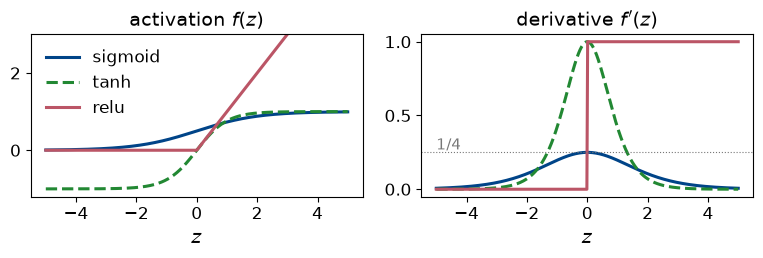

In [5]:
z = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for name, col, ls in (("sigmoid", BLUE, "-"), ("tanh", GREEN, "--"), ("relu", RED, "-")):
    f, fp = ACTIVATIONS[name]
    ax[0].plot(z, f(z), color=col, lw=2.2, ls=ls, label=name)
    ax[1].plot(z, fp(z), color=col, lw=2.2, ls=ls, label=name)
ax[0].set_ylim(-1.2, 3)
ax[0].set_title("activation $f(z)$")
ax[1].set_title("derivative $f'(z)$")
ax[1].axhline(0.25, color=GREY, lw=0.8, ls=":")
ax[1].text(-5, 0.27, "1/4", color=GREY, fontsize=11)
for a_ in ax:
    a_.set_xlabel("$z$")
ax[0].legend(frameon=False)
fig.tight_layout()
show(fig, "activations.png")

### Initialising the weights

Random, to break the symmetry. **And the scale matters.** A node sums $M$ inputs, $z=\sum_k w_k a_k + b$. With independent zero-mean weights of variance $\sigma_w^2$ and biases of variance $\sigma_b^2$, $\operatorname{Var}(z) = M\sigma_w^2\,\overline{a^2} + \sigma_b^2$, where $\overline{a^2}=\frac1M\sum_k a_k^2$ is the squared rms of the *incoming* activations. Usually $b\approx0$ at the start, so $\operatorname{Var}(z)\approx M\sigma_w^2\,\overline{a^2}$. For tanh near zero $a\approx z$, so each layer multiplies the variance by $M\sigma_w^2$. To keep the signal the same size in every layer we choose

$$\sigma_w^2 = 1/M \ \text{(tanh)},\qquad \sigma_w^2 = 2/M\ \text{(ReLU, which sets half of its inputs to zero)}.$$

This is what `create_layers` does (it uses $1/M$ for the sigmoid too, but there $f'\le 1/4$, so the gradients still shrink layer by layer). Below, a network with 10 hidden layers of 256 units gets random inputs, and we look at the activations and the gradients **before any training**.

tanh, sigma_w = 1.0000: saturated units (|a|>0.99) in layer 10:  87%,  |dC/dW| layer 1 / layer 10 = 3.2e+03 / 2.1e-01
tanh, sigma_w = 0.0100: saturated units (|a|>0.99) in layer 10:   0%,  |dC/dW| layer 1 / layer 10 = 5.5e-08 / 4.8e-08
tanh, sigma_w = 0.0625: saturated units (|a|>0.99) in layer 10:   0%,  |dC/dW| layer 1 / layer 10 = 2.4e-01 / 2.6e-01


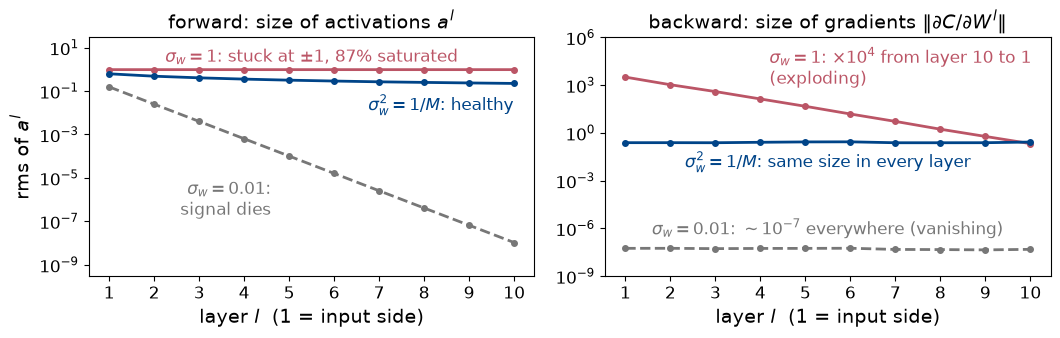

ReLU, M sigma_w^2 = 2: std of z^l in layer 1 / layer 10 = 1.41 / 1.238
ReLU, M sigma_w^2 = 1: std of z^l in layer 1 / layer 10 = 1.00 / 0.039


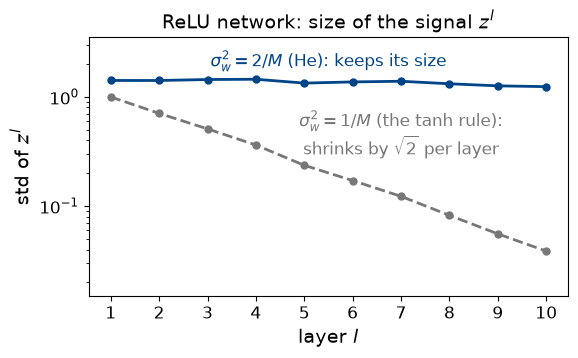

In [6]:
M, depth, n = 256, 10, 500
rng = np.random.default_rng(0)
X_init = rng.normal(size=(n, M))
Y_init = rng.normal(size=(n, 1))


def deep_network_stats(activation, sigma_w, seed=1):
    # Forward and backward pass through `depth` hidden layers of width M (no biases), linear output,
    # C = 1/2 mean (a - y)^2. Returns z^l and a^l of each hidden layer, and |dC/dW^l| for each layer.
    r = np.random.default_rng(seed)
    f, fp = ACTIVATIONS[activation]
    Ws = [r.normal(0, sigma_w, (M, M)) for _ in range(depth)] + [r.normal(0, np.sqrt(1 / M), (M, 1))]
    a, zs, As = X_init, [], [X_init]
    for l, W in enumerate(Ws):
        zs.append(a @ W)
        a = f(zs[-1]) if l < depth else zs[-1]
        As.append(a)
    delta = (a - Y_init) / n
    grad_norm = []
    for l in range(depth, -1, -1):
        grad_norm.append(np.linalg.norm(As[l].T @ delta))
        if l > 0:
            delta = (delta @ Ws[l].T) * fp(zs[l - 1])
    return zs[:depth], As[1:depth + 1], grad_norm[::-1][:depth]


def label_line(ax, x, y, text, col, dy=0, ha="left", va="center"):
    ax.annotate(text, (x, y), xytext=(6, dy), textcoords="offset points", color=col, ha=ha, va=va, fontsize=12)


# tanh: forward (size of the activations) and backward (size of the gradients), three choices of sigma_w
layer = np.arange(1, depth + 1)
tanh_cases = {"large": (1.0, RED, "-"), "small": (0.01, GREY, "--"), "1/M": (np.sqrt(1 / M), BLUE, "-")}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
res = {}
for key, (sigma_w, col, ls) in tanh_cases.items():
    zs, As, gn = deep_network_stats("tanh", sigma_w)
    res[key] = As, gn
    ax[0].semilogy(layer, [np.sqrt(np.mean(A**2)) for A in As], marker="o", color=col, ls=ls, lw=2, ms=4)
    ax[1].semilogy(layer, gn, marker="o", color=col, ls=ls, lw=2, ms=4)
    print(f"tanh, sigma_w = {sigma_w:.4f}: saturated units (|a|>0.99) in layer 10: {np.mean(np.abs(As[-1]) > 0.99):4.0%},  "
          f"|dC/dW| layer 1 / layer 10 = {gn[0]:.1e} / {gn[-1]:.1e}")
sat = np.mean(np.abs(res["large"][0][-1]) > 0.99)
ax[0].set_title("forward: size of activations $a^l$")
ax[0].set_ylabel(r"rms of $a^l$")
ax[0].set_ylim(3e-10, 30)
ax[0].text(5.5, 2.2, rf"$\sigma_w=1$: stuck at $\pm1$, {sat:.0%} saturated", color=RED, ha="center", fontsize=12)
ax[0].text(10, 0.07, r"$\sigma_w^2=1/M$: healthy", color=BLUE, ha="right", va="top", fontsize=12)
ax[0].text(4.6, 2e-7, r"$\sigma_w=0.01$:" "\nsignal dies", color=GREY, ha="right", fontsize=12)
gl, gs, gm = res["large"][1], res["small"][1], res["1/M"][1]
ax[1].set_title(r"backward: size of gradients $\|\partial C/\partial W^l\|$")
ax[1].set_ylim(1e-9, 1e6)
ax[1].text(4.2, gl[3] * 4, rf"$\sigma_w=1$: $\times10^{{{np.log10(gl[0] / gl[-1]):.0f}}}$ from layer 10 to 1" "\n(exploding)",
           color=RED, ha="left", va="bottom", fontsize=12)
ax[1].text(5.5, gm[4] / 4, r"$\sigma_w^2=1/M$: same size in every layer", color=BLUE, ha="center", va="top", fontsize=12)
ax[1].text(5.5, gs[4] * 4, rf"$\sigma_w=0.01$: $\sim10^{{{np.log10(np.mean(gs)):.0f}}}$ everywhere (vanishing)",
           color=GREY, ha="center", va="bottom", fontsize=12)
for a_ in ax:
    a_.set_xlabel("layer $l$  (1 = input side)")
    a_.set_xticks(layer)
fig.tight_layout()
show(fig, "init.png")

# ReLU: the same network, initialised with the tanh rule 1/M and with 2/M
fig, ax = plt.subplots(figsize=(6, 3.8))
for sigma2, col, ls, text, xy in ((2 / M, BLUE, "-", r"$\sigma_w^2=2/M$ (He): keeps its size", (5.5, 2.1)),
                                  (1 / M, GREY, "--", r"$\sigma_w^2=1/M$ (the tanh rule):" "\n" r"shrinks by $\sqrt{2}$ per layer",
                                   (7.0, 0.45))):
    zs, As, _ = deep_network_stats("relu", np.sqrt(sigma2))
    sz = np.array([z.std() for z in zs])
    ax.semilogy(layer, sz, marker="o", color=col, ls=ls, lw=2, ms=5)
    ax.text(*xy, text, color=col, ha="center", va="center", fontsize=12)
    print(f"ReLU, M sigma_w^2 = {M * sigma2:.0f}: std of z^l in layer 1 / layer 10 = {sz[0]:.2f} / {sz[-1]:.3f}")
ax.set_xlabel("layer $l$")
ax.set_ylabel(r"std of $z^l$")
ax.set_xticks(layer)
ax.set_ylim(0.015, 3.5)
ax.set_title("ReLU network: size of the signal $z^l$")
fig.tight_layout()
show(fig, "init_relu.png")

**What to see.**
- **Too large ($\sigma_w=1$):** the tanh units sit at $\pm1$ (saturated), and the gradients *grow* by a factor $\sim10^4$ on the way back from layer 10 to layer 1 (exploding).
- **Too small ($\sigma_w=0.01$):** the signal shrinks by a factor $\sqrt{M}\sigma_w=0.16$ per layer and dies, and the gradients are $\sim10^{-7}$ everywhere (vanishing).
- **$\sigma_w^2=1/M$:** activations of order one and gradients of the same size in every layer.

**The right scale depends on the activation.** The second figure is the same network with ReLU. With the tanh rule $\sigma_w^2=1/M$ the signal shrinks by $\sqrt2$ per layer, to $1/23$ of its size after 10 layers. The reason: ReLU sets the negative half of $z$ to zero, so it passes on only half the variance, $\overline{a^2}=\tfrac12\operatorname{Var}(z)$, and $\sigma_w^2=2/M$ (He) compensates. Change the activation function, and the initialisation has to change with it.

*Try it:* make the network deeper (`depth = 30`), or use the sigmoid with $\sigma_w^2=1/M$.

## 3. Output activation and cost function come in pairs

| Task | Output activation | Cost (one sample) | $\delta^L$ |
|---|---|---|---|
| regression, $y\in\mathbb R$ | linear, $a=z$ | $\frac12(a-y)^2$ | $a-y$ |
| binary, $y\in\{0,1\}$ | sigmoid | $-y\ln a-(1-y)\ln(1-a)$ | $a-y$ |
| $K$ classes, one-hot $\mathbf y$ | softmax | $-\sum_k y_k\ln a_k$ | $\mathbf a-\mathbf y$ |

For these pairs, $f'$ of the output activation cancels against $\partial C/\partial a$. For the sigmoid, $\sigma' = a(1-a)$ and $\partial C/\partial a = (a-y)/\big(a(1-a)\big)$, so $\delta^L = a-y$. The softmax is not element-wise: its $f'$ is the Jacobian $\partial a_k/\partial z_j = a_k(\delta_{kj}-a_j)$, but the same cancellation happens, $\delta_j = \sum_k(-y_k/a_k)\,a_k(\delta_{kj}-a_j) = a_j - y_j$. The gradient check in Section 1 confirmed all three. What happens *without* the cancellation, with a sigmoid output and the squared error? Then $\delta^L = (a-y)\,a(1-a)$: $\sigma'$ does not cancel, and $\sigma'\to0$ as $a\to0$. At $z=-5$ the error is 150 times smaller than with the cross entropy. The more confidently wrong, the *less* it learns:

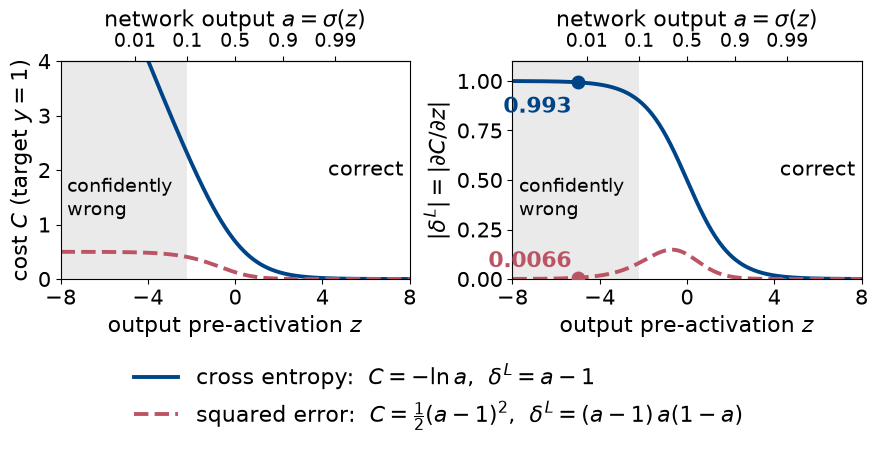

z = -5, y = 1:  a = 0.0067,  cross entropy delta = -0.993,  squared error delta = -0.0066  (ratio 150)


In [7]:
z = np.linspace(-8, 8, 400)
a = sigmoid(z)
a5 = sigmoid(-5.0)
FS = 16                                                      # large fonts: the figure is shown small on the slide
logit = lambda p: np.log(np.clip(p, 1e-300, None) / np.clip(1 - p, 1e-300, None))   # inverse of sigmoid
a_ticks = np.array([0.01, 0.1, 0.5, 0.9, 0.99])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.7))
ax[0].plot(z, -np.log(a), color=BLUE, lw=2.8, label=r"cross entropy:  $C=-\ln a$,  $\delta^L=a-1$")
ax[0].plot(z, 0.5 * (a - 1) ** 2, color=RED, lw=2.8, ls="--",
           label=r"squared error:  $C=\frac{1}{2}(a-1)^2$,  $\delta^L=(a-1)\,a(1-a)$")
ax[0].set_ylim(0, 4)
ax[0].set_ylabel("cost $C$ (target $y=1$)", fontsize=FS)
ax[1].plot(z, np.abs(a - 1), color=BLUE, lw=2.8)
ax[1].plot(z, np.abs(a - 1) * a * (1 - a), color=RED, lw=2.8, ls="--")
ax[1].set_ylim(0, 1.1)
ax[1].set_ylabel(r"$|\delta^L| = |\partial C/\partial z|$", fontsize=FS)
for val, col, y_text in ((1 - a5, BLUE, 0.84), ((1 - a5) * a5 * (1 - a5), RED, 0.06)):    # the point z = -5
    ax[1].plot(-5, val, "o", color=col, ms=9, zorder=3)
    ax[1].text(-5.3, y_text, f"{val:.2g}" if val < 0.1 else f"{val:.3f}", color=col, fontsize=FS,
               fontweight="bold", ha="right")
for a_ in ax:
    a_.set_xlim(-8, 8)
    a_.set_xticks([-8, -4, 0, 4, 8])
    a_.set_xlabel("output pre-activation $z$", fontsize=FS)
    a_.tick_params(labelsize=FS - 1)
    a_.axvspan(-8, np.log(0.1 / 0.9), color=GREY, alpha=0.15, lw=0)          # a < 0.1: confidently wrong
    a_.text(-7.7, 0.37 * a_.get_ylim()[1], "confidently\nwrong", fontsize=FS - 2, va="center")
    a_.text(7.7, 0.5 * a_.get_ylim()[1], "correct", fontsize=FS - 1, va="center", ha="right")
    top = a_.secondary_xaxis("top", functions=(sigmoid, logit))
    top.set_xticks(a_ticks)
    top.set_xticklabels([f"{p:g}" for p in a_ticks])
    top.tick_params(labelsize=FS - 2)
    top.set_xlabel(r"network output $a=\sigma(z)$", fontsize=FS)
fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.04), ncol=1,
           frameon=False, fontsize=FS)
fig.tight_layout()
show(fig, "delta_heads.png")

print(f"z = -5, y = 1:  a = {a5:.4f},  cross entropy delta = {a5 - 1:.3f},  "
      f"squared error delta = {(a5 - 1) * a5 * (1 - a5):.4f}  (ratio {1 / (a5 * (1 - a5)):.0f})")

### Which image trains the network?

We train a $784$–$100$–$10$ network with ReLU hidden units, the softmax and the cross entropy on the MNIST digits: 20 epochs, minibatches of 100, $\gamma=0.1$. This takes about a minute. Then we look at the test image the network is most sure about, and the one it is least sure about.

In [8]:
def load_mnist():
    # Looks for the repository's mnist.npz first; otherwise downloads with scikit-learn (once).
    for path in ("mnist.npz", os.path.join("..", "..", "BookML", "BookPrograms",
                                           "chapter10_convolutional_networks", "mnist.npz")):
        if os.path.exists(path):
            d = np.load(path)
            X_train = d["x_train"].reshape(len(d["x_train"]), -1) / 255.0
            X_test = d["x_test"].reshape(len(d["x_test"]), -1) / 255.0
            return X_train, d["y_train"].astype(int), X_test, d["y_test"].astype(int)
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)
    X, y = mnist.data / 255.0, mnist.target.astype(int)
    return X[:60000], y[:60000], X[60000:], y[60000:]


t0 = time.time()
X_train, y_train, X_test, y_test = load_mnist()
layers = create_layers([784, 100, 10], "relu", np.random.default_rng(2026))
layers, hist = train(X_train, one_hot(y_train, 10), layers, "relu", "softmax", gamma=0.1, epochs=20,
                     batch_size=100, X_test=X_test, y_test=y_test)
print(f"test accuracy after 20 epochs: {hist['test_accuracy'][-1]:.2%}  ({time.time() - t0:.0f} s)")

test accuracy after 20 epochs: 97.63%  (15 s)


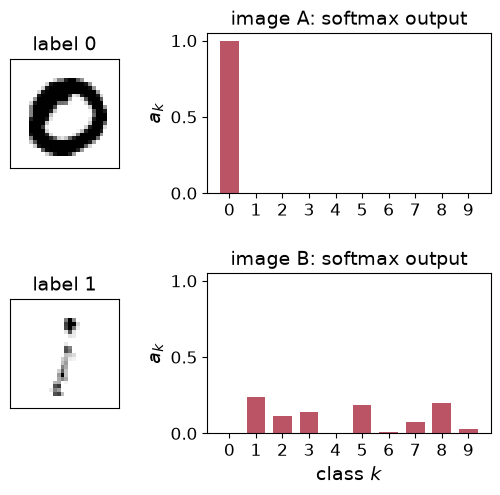

image A (label 0): delta^L = a - y = [-0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
image B (label 1): delta^L = a - y = [ 0.005 -0.76   0.115  0.141  0.     0.187  0.006  0.077  0.198  0.031]

image B: label 1,  one-hot y = [0 1 0 0 0 0 0 0 0 0]
  delta_1 = a_1 - y_1 = 0.24 - 1 = -0.76
  delta_8 = a_8 - y_8 = 0.20 - 0 = +0.20
  delta_5 = a_5 - y_5 = 0.19 - 0 = +0.19
  delta_3 = a_3 - y_3 = 0.14 - 0 = +0.14
  delta_2 = a_2 - y_2 = 0.11 - 0 = +0.11
  delta_7 = a_7 - y_7 = 0.08 - 0 = +0.08
  delta_9 = a_9 - y_9 = 0.03 - 0 = +0.03
  delta_6 = a_6 - y_6 = 0.01 - 0 = +0.01
  delta_0 = a_0 - y_0 = 0.00 - 0 = +0.00
  delta_4 = a_4 - y_4 = 0.00 - 0 = +0.00


In [9]:
P = predict(X_test, layers, "relu", "softmax")
pred, pmax = P.argmax(axis=1), P.max(axis=1)
i_A = int(np.argmax(np.where(pred == y_test, pmax, -1)))     # the most confident correct prediction
i_B = int(np.argmin(pmax))                                   # the least confident prediction

fig = plt.figure(figsize=(6.2, 5.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.6], wspace=0.45, hspace=0.5)
for row, (i, name) in enumerate(((i_A, "A"), (i_B, "B"))):
    axi = fig.add_subplot(gs[row, 0])
    axi.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    axi.set_title(f"label {y_test[i]}")
    axi.set_xticks([])
    axi.set_yticks([])
    axb = fig.add_subplot(gs[row, 1])
    axb.bar(np.arange(10), P[i], color=RED, width=0.7)
    axb.set_xticks(np.arange(10))
    axb.set_ylim(0, 1.05)
    axb.set_ylabel("$a_k$")
    axb.set_title(f"image {name}: softmax output")
axb.set_xlabel("class $k$")
show(fig, "mnist_question.png")

for i, name in ((i_A, "A"), (i_B, "B")):
    delta = P[i] - one_hot(y_test[i:i + 1], 10)[0]
    print(f"image {name} (label {y_test[i]}): delta^L = a - y = {np.round(delta, 3)}")

y_B = one_hot(y_test[i_B:i_B + 1], 10)[0]
delta_B = P[i_B] - y_B
print(f"\nimage B: label {y_test[i_B]},  one-hot y = {y_B.astype(int)}")
for k in np.argsort(-np.abs(delta_B)):                       # largest |delta_k| first
    print(f"  delta_{k} = a_{k} - y_{k} = {P[i_B, k]:.2f} - {y_B[k]:.0f} = {delta_B[k]:+.2f}")

For image A, $\delta^L\approx 0$: there is nothing left to learn from it. For image B, $\delta_1 = 0.24 - 1 = -0.76$, and the other classes get positive errors. The gradient raises the score of the correct class and lowers the others. The network learns most from the examples it gets wrong or is unsure about.

## 4. Universal approximation: ReLU units are kinks

One ReLU unit $v\,\mathrm{ReLU}(wx+b)$ is zero, then a straight line: it has one kink, at $x=-b/w$. Three units make a "hat", and a sum of hats can follow any continuous curve ("connect the dots"):

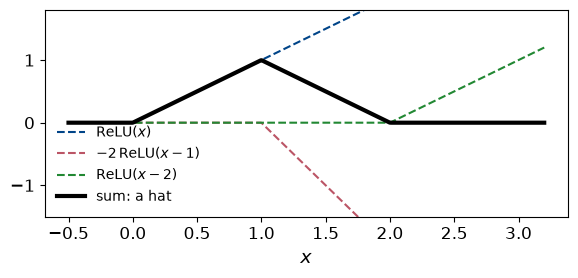

In [10]:
x = np.linspace(-0.5, 3.2, 500)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, relu(x), color=BLUE, ls="--", label=r"$\mathrm{ReLU}(x)$")
ax.plot(x, -2 * relu(x - 1), color=RED, ls="--", label=r"$-2\,\mathrm{ReLU}(x-1)$")
ax.plot(x, relu(x - 2), color=GREEN, ls="--", label=r"$\mathrm{ReLU}(x-2)$")
ax.plot(x, relu(x) - 2 * relu(x - 1) + relu(x - 2), color="k", lw=3, label="sum: a hat")
ax.set_ylim(-1.5, 1.8)
ax.set_xlabel("$x$")
ax.legend(frameon=False, fontsize=10, loc="lower left")
fig.tight_layout()
show(fig, "relu_hat.png")

Training finds such a construction by itself. We fit a $1$–$50$–$1$ ReLU network to noisy data from the Runge function $1/(1+25x^2)$ (the data of Project 1): 20 000 steps of plain gradient descent. The output is piecewise linear, and we mark its kinks.

test MSE 0.0094 (the noise variance is 0.01); 50 kinks inside [-1, 1], 15 distinct


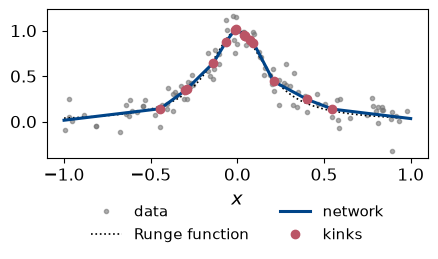

In [11]:
def runge_data(n=100, sigma=0.1, seed=2026):
    # Project 1: x uniform on [-1, 1], y = 1/(1 + 25 x^2) + noise; a training and a test set.
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(-1, 1, n))
    y = 1.0 / (1.0 + 25 * x ** 2) + rng.normal(0, sigma, n)
    x_test = np.sort(rng.uniform(-1, 1, n))
    y_test = 1.0 / (1.0 + 25 * x_test ** 2) + rng.normal(0, sigma, n)
    return x[:, None], y[:, None], x_test[:, None], y_test[:, None]


X, Y, Xt, Yt = runge_data()
layers = create_layers([1, 50, 1], "relu", np.random.default_rng(2026))
layers, hist = train(X, Y, layers, "relu", "mse", gamma=0.1, epochs=20000)
(W1, b1), (W2, b2) = layers
kinks = -b1 / W1[0]
kinks = np.sort(kinks[(kinks > -1) & (kinks < 1) & (np.abs(W2[:, 0] * W1[0]) > 1e-3)])
kinks_distinct = np.unique(np.round(kinks, 3))            # several units often share one kink
print(f"test MSE {np.mean((predict(Xt, layers, 'relu') - Yt) ** 2):.4f} (the noise variance is 0.01); "
      f"{len(kinks)} kinks inside [-1, 1], {len(kinks_distinct)} distinct")

xx = np.linspace(-1, 1, 801)[:, None]
fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.plot(X, Y, "o", color=GREY, ms=3, alpha=0.6, label="data")
ax.plot(xx, 1 / (1 + 25 * xx ** 2), color="k", lw=1.2, ls=":", label="Runge function")
ax.plot(xx, predict(xx, layers, "relu"), color=BLUE, lw=2.2, label="network")
ax.plot(kinks_distinct, predict(kinks_distinct[:, None], layers, "relu")[:, 0], "o", color=RED, ms=6, label="kinks")
ax.set_xlabel("$x$")
ax.legend(frameon=False, fontsize=11, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
fig.tight_layout()
show(fig, "runge_kinks.png")

*Try it:* use `"identity"` as the hidden activation. What does the network fit now, and why?

### Universal approximation: the precise statements

**The theorem** (Leshno et al. 1993). Let $f$ be continuous. One-hidden-layer networks $G(\mathbf x)=\sum_{j=1}^N v_j f(\mathbf w_j^T\mathbf x+b_j)$ can approximate every continuous $F$ on a compact $K\subset\mathbb R^d$ to any accuracy, $\sup_{\mathbf x\in K}|F(\mathbf x)-G(\mathbf x)|<\epsilon$, **if and only if $f$ is not a polynomial**. (If $f$ has degree $p$, so has $G$, for any $N$.) Earlier versions: Cybenko 1989 (sigmoids), Hornik 1991 (any bounded, non-constant $f$; also in mean square).

**How many units?**
- 1D, ReLU: the hat construction is the piecewise-linear interpolant. For $|F'|\le L$ on $[a,b]$, $\sup_x|F-G|\le L(b-a)/(2N)$.
- $d$ dimensions, grid-like constructions: error $\sim N^{-1/d}$, so $\sim\epsilon^{-d}$ units, the curse of dimensionality.
- Smooth enough $F$ (Barron 1993): if $C_F=\int|\boldsymbol\omega|\,|\hat F(\boldsymbol\omega)|\,d\boldsymbol\omega<\infty$, a sigmoid network reaches mean-square error $\lesssim C_F^2/N$, independent of $d$.
- Depth: some functions need exponentially many units in one hidden layer, but only polynomially many in a deep network (Telgarsky 2016).

None of this says whether gradient descent *finds* these weights.

## 5. Neural networks for differential equations

We want to solve, for example, $g'(x) + \alpha g(x) = 0$ with $g(0)=g_0$. There are no data $g(x_i)$, only the equation. The method has three ingredients:

1. A **trial solution** $g_t(x) = h(x) + B(x)\,N(x)$ that satisfies the conditions for *any* network $N$: $h$ satisfies the conditions, and $B=0$ where they are imposed.
2. The **residual**, here $r(x) = g_t'(x) + \alpha g_t(x)$, which is zero for the exact solution.
3. The **cost** $C = \frac1n\sum_i r(x_i)^2$ at *collocation points* $x_i$ that we choose ourselves.

The residual contains $g_t'$, so we need the derivative of the network with respect to its **input** $x$. Writing this by hand is tedious, so we let JAX do it. The network is the same as before, written in `jax.numpy` with a linear output.

In [12]:
JAX_ACTIVATIONS = {"tanh": jnp.tanh, "sigmoid": jax.nn.sigmoid, "relu": jax.nn.relu, "gelu": jax.nn.gelu}


def network(layers, X, activation="tanh"):
    # N(x): the forward pass with a linear output; X has one row per point (one column per input).
    f = JAX_ACTIVATIONS[activation]
    a = X
    for l, (W, b) in enumerate(layers):
        z = a @ W + b
        a = f(z) if l < len(layers) - 1 else z
    return a[:, 0]


def d_dxk(fun, k):
    # The derivative of fun(layers, X) with respect to input column k, row by row.
    # Nest it for higher derivatives: d_dxk(d_dxk(u, 0), 0) is the second derivative in x_0.
    def wrapped(layers, X):
        def one_row(xk, row):
            return fun(layers, row.at[k].set(xk)[None, :])[0]
        return jax.vmap(jax.grad(one_row))(X[:, k], X)
    return wrapped


def adam_minimise(cost_fn, params, n_iter=2000, gamma=1e-2, b1=0.9, b2=0.999, eps=1e-8, every=50, trace_fn=None,
                  n_decay=0):
    # Adam for any nested structure of arrays. jax.value_and_grad does the backward pass for us.
    # With n_decay > 0 the learning rate falls from gamma to gamma/100 over the last n_decay steps:
    # a large learning rate makes the cost jump around, and the decay lets it settle at the end.
    tree = jax.tree_util

    @jax.jit
    def step(params, m, v, it, lr):
        c, g = jax.value_and_grad(cost_fn)(params)
        m = tree.tree_map(lambda m_, g_: b1 * m_ + (1 - b1) * g_, m, g)
        v = tree.tree_map(lambda v_, g_: b2 * v_ + (1 - b2) * g_ ** 2, v, g)
        params = tree.tree_map(lambda p, m_, v_: p - lr * (m_ / (1 - b1 ** it)) / (jnp.sqrt(v_ / (1 - b2 ** it)) + eps),
                               params, m, v)
        return params, m, v, c

    m = tree.tree_map(jnp.zeros_like, params)
    v = tree.tree_map(jnp.zeros_like, params)
    scalars = lambda it, lr: (jnp.asarray(it, dtype=float), jnp.asarray(lr, dtype=float))
    t0 = time.perf_counter()
    step = step.lower(params, m, v, *scalars(1, gamma)).compile()      # compile first: the loop then times training only
    t1 = time.perf_counter()
    history = []
    for it in range(1, n_iter + 1):
        k = it - (n_iter - n_decay)                     # > 0 during the last n_decay steps
        lr = gamma if k <= 0 else gamma * 0.01 ** (k / n_decay)
        params, m, v, c = step(params, m, v, *scalars(it, lr))
        if it == 1 or it % every == 0 or it == n_iter:
            extra = tuple(np.atleast_1d(np.asarray(trace_fn(params)))) if trace_fn else ()
            history.append((it, float(c)) + extra)
    jax.block_until_ready(params)
    adam_minimise.timing = {"compile": t1 - t0, "train": time.perf_counter() - t1, "steps": n_iter}
    return params, np.array(history)


def solve_de(residual, sizes, X, n_iter=2000, gamma=1e-2, seed=1, n_decay=0):
    # Minimise the mean squared residual at the collocation points X.
    layers = to_jax(create_layers(sizes, "tanh", np.random.default_rng(seed)))
    X = jnp.asarray(X)
    return adam_minimise(lambda layers: jnp.mean(residual(layers, X) ** 2), layers, n_iter=n_iter, gamma=gamma,
                         n_decay=n_decay)

### Example: exponential decay

With $\alpha=2$ and $g_0=10$, the trial solution is $g_t = g_0 + x\,N(x)$, so $g_t(0)=g_0$ whatever the network does. Its derivative is $g_t' = N + xN'$, which `d_dxk` computes for us.

final cost 1.6e-03,  max error 2.5e-03  (1 s)


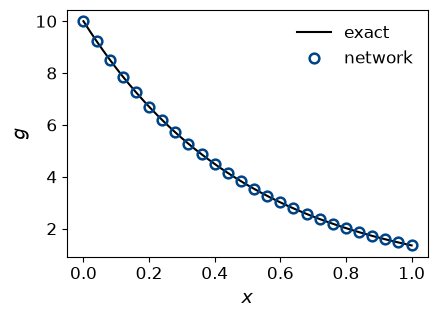

In [13]:
ALPHA, G0 = 2.0, 10.0


def trial_decay(layers, X):
    return G0 + X[:, 0] * network(layers, X)


def residual_decay(layers, X):
    return d_dxk(trial_decay, 0)(layers, X) + ALPHA * trial_decay(layers, X)


t0 = time.time()
X_col = np.linspace(0, 1, 50)[:, None]                     # 50 collocation points
layers_decay, hist = solve_de(residual_decay, [1, 40, 40, 1], X_col, n_iter=4000, gamma=2e-2, n_decay=1000)
xx = np.linspace(0, 1, 401)
g = np.asarray(trial_decay(layers_decay, jnp.asarray(xx[:, None])))
print(f"final cost {hist[-1, 1]:.1e},  max error {np.abs(g - G0 * np.exp(-ALPHA * xx)).max():.1e}  "
      f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.plot(xx, G0 * np.exp(-ALPHA * xx), color="k", lw=1.5, label="exact")
ax.plot(xx[::16], g[::16], "o", color=BLUE, ms=7, mfc="none", mew=1.8, label="network")
ax.set_xlabel("$x$")
ax.set_ylabel("$g$")
ax.legend(frameon=False)
fig.tight_layout()
show(fig, "ode_decay.png")

### The activation function matters even more now

For one hidden layer, $N(x) = \sum_j v_j f(w_jx+b_j) + c$ gives $N''(x) = \sum_j v_j w_j^2 f''(w_jx+b_j)$. For ReLU, $f''=0$, so a ReLU network has **no second derivative at all**, whatever the weights. Here is the largest $|N''|$ of a randomly initialised $[1,20,20,1]$ network on $[-2,2]$:

In [14]:
X_check = jnp.linspace(-2, 2, 200)[:, None]
for act in ("tanh", "gelu", "sigmoid", "relu"):
    layers_check = to_jax(create_layers([1, 20, 20, 1], "relu" if act == "relu" else "sigmoid",
                                        np.random.default_rng(2026)))
    N_xx = d_dxk(d_dxk(lambda L, X, act=act: network(L, X, act), 0), 0)(layers_check, X_check)
    print(f"{act:8s} max |N''| = {float(jnp.max(jnp.abs(N_xx))):.3g}")

tanh     max |N''| = 2.91
gelu     max |N''| = 1.16
sigmoid  max |N''| = 0.0591
relu     max |N''| = 0


### Boundary conditions in the trial solution, and a comparison with standard methods

The recipe is $g_t = h(x) + B(x)\,N(x)$, where $h$ satisfies the conditions and $B=0$ wherever a condition is imposed:

| Conditions | Trial solution $g_t$ |
|---|---|
| $g(0)=g(1)=0$ | $x(1-x)\,N$ |
| $g(0)=a$, $g(1)=b$ | $a+(b-a)x+x(1-x)\,N$ |
| $g(0)=g_0$, $g'(0)=v_0$ | $g_0+v_0x+x^2N$ |
| $g(0)=a$, $g'(1)=b$ | $a+bx+x\big(N(x)-N(1)-N'(1)\big)$ |

The last row shows that a condition on the derivative is possible, but it needs a trick: check that $g_t'(1) = b + N(1) - N(1) - N'(1) + N'(1) = b$. For a curved boundary in 2D or 3D, building $g_t$ by hand becomes impractical.

Two more equations, both with tanh networks:
- **Logistic growth** $g' - 2g(1-g) = 0$, $g(0)=1.2$. This equation is non-linear, but it has the same trial solution $g_0 + xN$; only the residual changes. We compare with forward Euler, which follows the slope for one step, $g_{n+1}=g_n+\Delta t\,g'(t_n)$ (error $\propto\Delta t$), and with the classic fourth-order Runge–Kutta method (RK4: four slope evaluations per step, error $\propto\Delta t^4$).
- **Poisson** $g'' + (3x+x^2)e^x = 0$, $g(0)=g(1)=0$. The trial solution is $x(1-x)N$, which is zero at both ends. We compare with finite differences: $g''(x_i)\approx(g_{i+1}-2g_i+g_{i-1})/\Delta x^2$ turns the equation into a tridiagonal linear system (error $\propto\Delta x^2$).

*Guess first:* which is more accurate, the network or the standard method? Which is faster?

logistic growth:                max error   wall-clock time
  forward Euler, dt = 0.1         9.9e-03     0.009 ms
  forward Euler, dt = 0.01        8.9e-04     0.041 ms
  RK4, dt = 0.01                 1.8e-10     0.142 ms
  network                        1.0e-04     536 ms  (4000 Adam steps, 50 collocation points, 0.13 ms/step; compilation 192 ms)
Poisson:
  finite differences, dx = 0.1   2.2e-03     0.019 ms
  finite differences, dx = 0.01  2.2e-05     0.124 ms
  network                        1.3e-05     777 ms  (4000 Adam steps, 60 collocation points, 0.19 ms/step; compilation 440 ms)


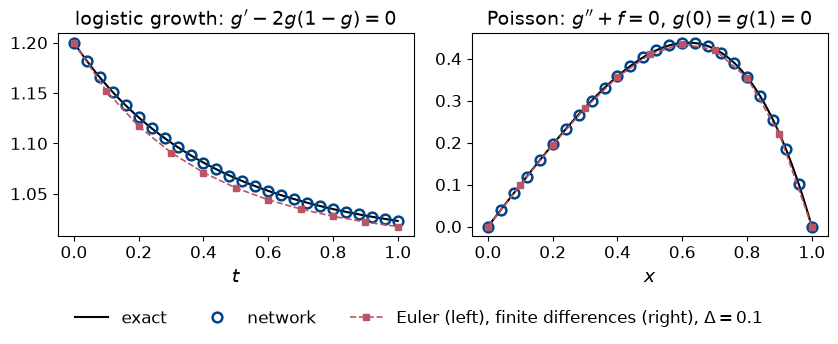

In [15]:
G0_LOG = 1.2


def trial_logistic(layers, X):
    return G0_LOG + X[:, 0] * network(layers, X)


def residual_logistic(layers, X):
    g = trial_logistic(layers, X)
    return d_dxk(trial_logistic, 0)(layers, X) - 2.0 * g * (1 - g)


def trial_poisson(layers, X):
    x = X[:, 0]
    return x * (1 - x) * network(layers, X)


def residual_poisson(layers, X):
    return d_dxk(d_dxk(trial_poisson, 0), 0)(layers, X) + (3 * X[:, 0] + X[:, 0] ** 2) * jnp.exp(X[:, 0])


exact_logistic = lambda t: G0_LOG / (G0_LOG + (1 - G0_LOG) * np.exp(-2 * t))
exact_poisson = lambda x: x * (1 - x) * np.exp(x)


def euler_logistic(n_steps):
    t = np.linspace(0, 1, n_steps + 1)
    g = np.empty(n_steps + 1)
    g[0] = G0_LOG
    for i in range(n_steps):
        g[i + 1] = g[i] + (1 / n_steps) * 2.0 * g[i] * (1 - g[i])
    return t, g


def rk4_logistic(n_steps):
    t = np.linspace(0, 1, n_steps + 1)
    g = np.empty(n_steps + 1)
    g[0] = G0_LOG
    rhs = lambda g: 2.0 * g * (1 - g)
    h = 1 / n_steps
    for i in range(n_steps):
        k1 = rhs(g[i])
        k2 = rhs(g[i] + h / 2 * k1)
        k3 = rhs(g[i] + h / 2 * k2)
        k4 = rhs(g[i] + h * k3)
        g[i + 1] = g[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, g


def fd_poisson(n):
    # -u'' = f with the three-point formula: a tridiagonal system for the n - 1 interior points.
    x = np.linspace(0, 1, n + 1)
    A = (2 * np.eye(n - 1) - np.eye(n - 1, k=1) - np.eye(n - 1, k=-1)) * n ** 2
    u = np.zeros(n + 1)
    u[1:-1] = np.linalg.solve(A, (3 * x[1:-1] + x[1:-1] ** 2) * np.exp(x[1:-1]))
    return x, u


def wall_time(f, n=500):
    # Mean wall-clock time of f() over n runs, in ms.
    t0 = time.perf_counter()
    for _ in range(n):
        f()
    return 1e3 * (time.perf_counter() - t0) / n


def network_time(timing, n_col):
    # Training time after JIT compilation; the compilation is reported separately.
    return (f"{1e3 * timing['train']:.0f} ms  ({timing['steps']} Adam steps, {n_col} collocation points, "
            f"{1e3 * timing['train'] / timing['steps']:.2f} ms/step; compilation {1e3 * timing['compile']:.0f} ms)")


X_log, X_poi = np.linspace(0, 1, 50)[:, None], np.linspace(0, 1, 60)[:, None]
layers_log, _ = solve_de(residual_logistic, [1, 40, 40, 1], X_log, n_iter=4000, gamma=2e-2, n_decay=1000)
time_log = adam_minimise.timing
layers_poi, _ = solve_de(residual_poisson, [1, 30, 30, 1], X_poi, n_iter=4000, gamma=1e-2)
time_poi = adam_minimise.timing
g_log = np.asarray(trial_logistic(layers_log, jnp.asarray(xx[:, None])))
g_poi = np.asarray(trial_poisson(layers_poi, jnp.asarray(xx[:, None])))
print("logistic growth:                max error   wall-clock time")
for n_steps in (10, 100):
    t, ge = euler_logistic(n_steps)
    print(f"  forward Euler, dt = {1 / n_steps:<5}       {np.abs(ge - exact_logistic(t)).max():.1e}     "
          f"{wall_time(lambda: euler_logistic(n_steps)):.3f} ms")
t, gr = rk4_logistic(100)
print(f"  RK4, dt = 0.01                 {np.abs(gr - exact_logistic(t)).max():.1e}     "
      f"{wall_time(lambda: rk4_logistic(100)):.3f} ms")
print(f"  network                        {np.abs(g_log - exact_logistic(xx)).max():.1e}     "
      f"{network_time(time_log, len(X_log))}")
print("Poisson:")
for n_int in (10, 100):
    x, u = fd_poisson(n_int)
    print(f"  finite differences, dx = {1 / n_int:<5} {np.abs(u - exact_poisson(x)).max():.1e}     "
          f"{wall_time(lambda: fd_poisson(n_int)):.3f} ms")
print(f"  network                        {np.abs(g_poi - exact_poisson(xx)).max():.1e}     "
      f"{network_time(time_poi, len(X_poi))}")

fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.2))
t10, g10 = euler_logistic(10)
ax[0].plot(xx, exact_logistic(xx), color="k", lw=1.5, label="exact")
ax[0].plot(xx[::16], g_log[::16], "o", color=BLUE, ms=7, mfc="none", mew=1.8, label="network")
ax[0].plot(t10, g10, "s--", color=RED, ms=5, lw=1.2, label=r"Euler, $\Delta t=0.1$")
ax[0].set_title("logistic growth: $g'-2g(1-g)=0$")
ax[0].set_xlabel("$t$")
x10, u10 = fd_poisson(10)
ax[1].plot(xx, exact_poisson(xx), color="k", lw=1.5, label="exact")
ax[1].plot(xx[::16], g_poi[::16], "o", color=BLUE, ms=7, mfc="none", mew=1.8, label="network")
ax[1].plot(x10, u10, "s--", color=RED, ms=5, lw=1.2, label=r"finite diff., $\Delta x=0.1$")
ax[1].set_title("Poisson: $g''+f=0$, $g(0)=g(1)=0$")
ax[1].set_xlabel("$x$")
fig.tight_layout()
h, _ = ax[0].get_legend_handles_labels()
fig.legend(h, ["exact", "network", r"Euler (left), finite differences (right), $\Delta=0.1$"],
           loc="upper center", bbox_to_anchor=(0.5, 0.04), ncol=3, frameon=False)
show(fig, "ode_results.png")

The network beats forward Euler, but RK4 is far more accurate. And Euler, RK4 and finite differences take a tenth of a millisecond or less, while the network needs 4000 training steps, about half a second. For simple equations like these, the standard methods win. (The plots use $\Delta=0.1$ so that the points are visible; the printed errors also use $\Delta=0.01$.)

### A partial differential equation: diffusion

$$\frac{\partial g}{\partial t}-\frac{\partial^2 g}{\partial x^2}=0,\qquad g(0,t)=g(1,t)=0,\qquad g(x,0)=\sin\pi x,$$

with the exact solution $g = e^{-\pi^2 t}\sin\pi x$. The network now has two inputs, $N(x,t)$. One trial solution handles all three conditions:

$$g_t = (1-t)\sin\pi x + x(1-x)\,t\,N(x,t).$$

network: max error 1.0e-02, RMSE 1.8e-03, error at t = 0: 0.0e+00
  training 1403 ms  (800 Adam steps, 400 collocation points, 1.75 ms/step; compilation 441 ms)
explicit finite differences, dx = 0.05: max error 1.5e-03
  wall-clock time 2.52 ms  (800 time steps, without the error tracking)


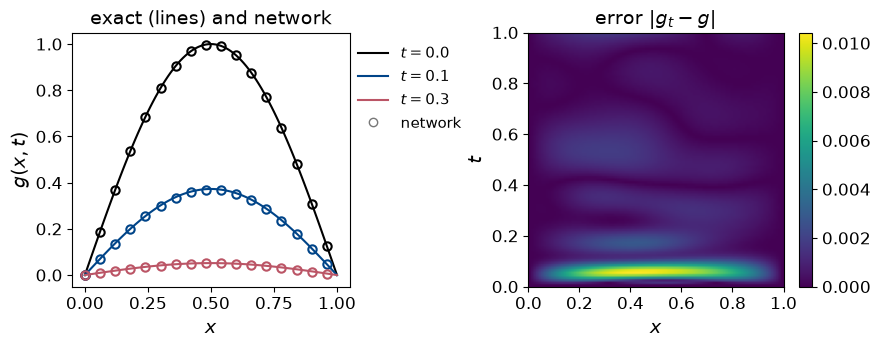

In [16]:
def trial_diffusion(layers, X):
    x, t = X[:, 0], X[:, 1]
    return (1 - t) * jnp.sin(jnp.pi * x) + x * (1 - x) * t * network(layers, X)


def residual_diffusion(layers, X):
    g_t = d_dxk(trial_diffusion, 1)                  # derivative with respect to column 1 (t)
    g_xx = d_dxk(d_dxk(trial_diffusion, 0), 0)       # second derivative with respect to column 0 (x)
    return g_t(layers, X) - g_xx(layers, X)


exact_diffusion = lambda x, t, D=1.0: np.exp(-D * np.pi ** 2 * t) * np.sin(np.pi * x)


def evaluate_diffusion(g_fun, layers, n_eval=101):
    # Errors on a fine grid: max, RMSE, max at t = 0, and the error map.
    xe = np.linspace(0, 1, n_eval)
    Xe, Te = np.meshgrid(xe, xe, indexing="ij")
    g = np.asarray(g_fun(layers, jnp.asarray(np.column_stack([Xe.ravel(), Te.ravel()])))).reshape(n_eval, n_eval)
    err = np.abs(g - exact_diffusion(Xe, Te))
    return {"max": err.max(), "rmse": np.sqrt(np.mean(err ** 2)), "t0": err[:, 0].max(), "map": err, "x": xe, "g": g}


def fd_diffusion(nx=21, r=0.5, track_error=True):
    # Explicit finite differences, dt = r dx^2 (r <= 1/2 for stability), up to t = 1.
    x = np.linspace(0, 1, nx)
    dt = r * (x[1] - x[0]) ** 2
    u, t, max_err = np.sin(np.pi * x), 0.0, 0.0
    for _ in range(int(round(1 / dt))):
        u[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
        t += dt
        if track_error:
            max_err = max(max_err, np.abs(u - exact_diffusion(x, t)).max())
    return max_err


xs = np.linspace(0, 1, 20)
Xg, Tg = np.meshgrid(xs, xs, indexing="ij")
X_col = np.column_stack([Xg.ravel(), Tg.ravel()])           # 20 x 20 collocation points
layers_diff, _ = solve_de(residual_diffusion, [2, 30, 30, 1], X_col, n_iter=800, gamma=1e-2)
time_diff = adam_minimise.timing
hard = evaluate_diffusion(trial_diffusion, layers_diff)
print(f"network: max error {hard['max']:.1e}, RMSE {hard['rmse']:.1e}, error at t = 0: {hard['t0']:.1e}")
print(f"  training {network_time(time_diff, len(X_col))}")
print(f"explicit finite differences, dx = 0.05: max error {fd_diffusion():.1e}")
print(f"  wall-clock time {wall_time(lambda: fd_diffusion(track_error=False), n=100):.2f} ms  "
      f"({int(round(1 / (0.5 * 0.05 ** 2)))} time steps, without the error tracking)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.6})
for ts, col in zip((0.0, 0.1, 0.3), ("k", BLUE, RED)):
    it = int(round(ts * 100))
    ax[0].plot(hard["x"], exact_diffusion(hard["x"], ts), color=col, lw=1.5, label=f"$t={ts:.1f}$")
    ax[0].plot(hard["x"][::6], hard["g"][::6, it], "o", color=col, ms=6, mfc="none", mew=1.5)
ax[0].plot([], [], "o", color=GREY, mfc="none", label="network")
ax[0].set_xlabel("$x$")
ax[0].set_ylabel("$g(x,t)$")
ax[0].set_title("exact (lines) and network")
ax[0].legend(frameon=False, fontsize=11, loc="upper left", bbox_to_anchor=(0.98, 1.0))
im = ax[1].imshow(hard["map"].T, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
fig.colorbar(im, ax=ax[1])
ax[1].set_xlabel("$x$")
ax[1].set_ylabel("$t$")
ax[1].set_title("error $|g_t-g|$")
show(fig, "diffusion.png")

The error is exactly zero on the three edges, because the conditions are built into $g_t$. It is largest near $t=0$, where the solution changes fastest.

### Soft constraints: physics-informed neural networks (PINNs)

Instead of building $g_t$ by hand, we let the network *be* the solution ($u$, like $g$ before), $u\approx N(x,t)$, and add the conditions to the cost as penalties:

$$L = L_\mathrm{PDE} + \lambda\,(L_\mathrm{IC} + L_\mathrm{BC}).$$

The PDE term uses points inside the domain, $L_\mathrm{IC}$ points on $t=0$, and $L_\mathrm{BC}$ points on $x=0$ and $x=1$.

In [17]:
def u_net(layers, X):
    return network(layers, X)


u_t = d_dxk(u_net, 1)
u_xx = d_dxk(d_dxk(u_net, 0), 0)

X_int = jnp.asarray(np.column_stack([Xg[1:-1, 1:-1].ravel(), Tg[1:-1, 1:-1].ravel()]))   # 18 x 18 interior points
X_ic = jnp.asarray(np.column_stack([xs, np.zeros(20)]))                                  # t = 0
X_left = jnp.asarray(np.column_stack([np.zeros(20), xs]))                                # x = 0
X_right = jnp.asarray(np.column_stack([np.ones(20), xs]))                                # x = 1


def pinn_cost(layers, lam=10.0, u=u_net):
    # u(layers, X) is the network that approximates the solution (tanh by default).
    L_pde = jnp.mean((d_dxk(u, 1)(layers, X_int) - d_dxk(d_dxk(u, 0), 0)(layers, X_int)) ** 2)
    L_ic = jnp.mean((u(layers, X_ic) - jnp.sin(jnp.pi * X_ic[:, 0])) ** 2)
    L_bc = jnp.mean(u(layers, X_left) ** 2) + jnp.mean(u(layers, X_right) ** 2)
    return L_pde + lam * (L_ic + L_bc)


t0 = time.time()
layers_pinn, _ = adam_minimise(pinn_cost, to_jax(create_layers([2, 30, 30, 1], "tanh", np.random.default_rng(1))),
                               n_iter=4000, gamma=1e-2)
soft = evaluate_diffusion(u_net, layers_pinn)
print(f"({time.time() - t0:.0f} s)\n")
print(f"{'':22s}{'RMSE':>10s}{'error at t=0':>15s}")
print(f"{'hard (trial solution)':22s}{hard['rmse']:10.1e}{hard['t0']:15.1e}")
print(f"{'soft, lambda = 10':22s}{soft['rmse']:10.1e}{soft['t0']:15.1e}")

(6 s)

                            RMSE   error at t=0
hard (trial solution)    1.8e-03        0.0e+00
soft, lambda = 10        6.5e-03        6.3e-03


If you *can* build a trial solution, do: it is exact on the boundary and more accurate. Soft constraints are flexible, but the conditions only hold approximately, and $\lambda$ must be tuned.

*Try it:* change $\lambda$ to 1 or 100 in `pinn_cost` (e.g. `lambda L: pinn_cost(L, lam=100.0)`). What happens to the error at $t=0$, and to the error inside the domain?

**Think first: a small residual, a wrong answer.** What happens if we use a ReLU network here? Automatic differentiation gives $\partial_x^2N = 0$ (ReLU has no curvature), so $L_\mathrm{PDE}$ is just the mean of $(\partial_tN)^2$. What will the optimiser do with $N$? The cell below trains a ReLU PINN with the same points, $\lambda=10$, network size and optimiser as the tanh PINN above.


(1 s)

ReLU PINN:              final cost 5.7e-04,  RMSE 0.65
hard (trial solution):  RMSE 1.8e-03
largest |d^2u/dx^2| of the ReLU network at the interior points: 0.0e+00


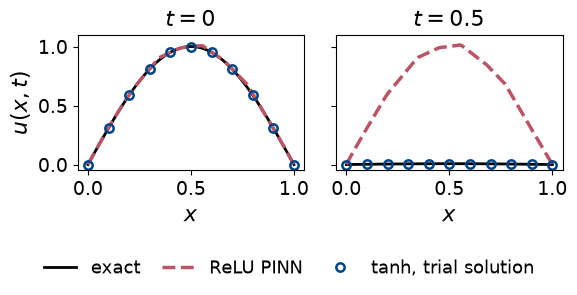

In [18]:
def u_relu(layers, X):
    return network(layers, X, "relu")


t0 = time.time()
layers_relu, hist_relu = adam_minimise(lambda L: pinn_cost(L, u=u_relu),
                                       to_jax(create_layers([2, 30, 30, 1], "relu", np.random.default_rng(1))),
                                       n_iter=4000, gamma=1e-2)
relu_pinn = evaluate_diffusion(u_relu, layers_relu)
print(f"({time.time() - t0:.0f} s)\n")
print(f"ReLU PINN:              final cost {hist_relu[-1, 1]:.1e},  RMSE {relu_pinn['rmse']:.2f}")
print(f"hard (trial solution):  RMSE {hard['rmse']:.1e}")
print(f"largest |d^2u/dx^2| of the ReLU network at the interior points: "
      f"{float(jnp.max(jnp.abs(d_dxk(d_dxk(u_relu, 0), 0)(layers_relu, X_int)))):.1e}")

T_RELU = (0.0, 0.5)
fig, ax = plt.subplots(1, 2, figsize=(6, 2.6), sharey=True)
for a_, ts in zip(ax, T_RELU):
    it = int(round(ts * 100))
    a_.plot(relu_pinn["x"], exact_diffusion(relu_pinn["x"], ts), color="k", lw=2, label="exact")
    a_.plot(relu_pinn["x"], relu_pinn["g"][:, it], color=RED, lw=2.5, ls="--", label="ReLU PINN")
    a_.plot(hard["x"][::10], hard["g"][::10, it], "o", color=BLUE, ms=6, mfc="none", mew=1.8,
            label="tanh, trial solution")
    a_.set_title(f"$t = {ts:g}$", fontsize=16)
    a_.set_xlabel("$x$", fontsize=16)
    a_.set_xticks([0, 0.5, 1])
    a_.tick_params(labelsize=14)
ax[0].set_ylabel("$u(x,t)$", fontsize=16)
ax[0].set_yticks([0, 0.5, 1])
ax[0].set_ylim(-0.05, 1.1)
fig.tight_layout()
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3, frameon=False, fontsize=13,
           handlelength=1.8, columnspacing=1.2)
show(fig, "relu_pinn.png")


The final cost is small, $6\times10^{-4}$, but the RMSE is $0.65$, against $1.8\times10^{-3}$ for the trial solution. The network has learned $N\approx\sin\pi x$ for *all* $t$ (the dashed curves lie on top of each other): the initial and boundary conditions hold, $\partial_tN\approx 0$ and $\partial_x^2N=0$, so the residual is almost zero, but the solution never diffuses. **A small residual does not mean a correct solution.**

### Why soft constraints at all? Inverse problems

Now the diffusion coefficient in $\partial_t u - D\,\partial_x^2 u = 0$ is **unknown**. We have no initial or boundary conditions, only 40 noisy measurements of the solution (made with the true $D=0.5$). We treat $D$ as one more trainable parameter:

$$L(N, D) = \frac1n\sum_j\big(\partial_t N - D\,\partial_x^2 N\big)_j^2 + \lambda\,\frac1{40}\sum_i\big(N(x_i,t_i) - y_i\big)^2 .$$

No trial solution is possible here, so soft constraints are the only option.

start D = 2.0:  recovered D = 0.5141
start D = 1.0:  recovered D = 0.5149
start D = 0.1:  recovered D = 0.5124
five times more noise:  recovered D = 0.6901  (19 s)


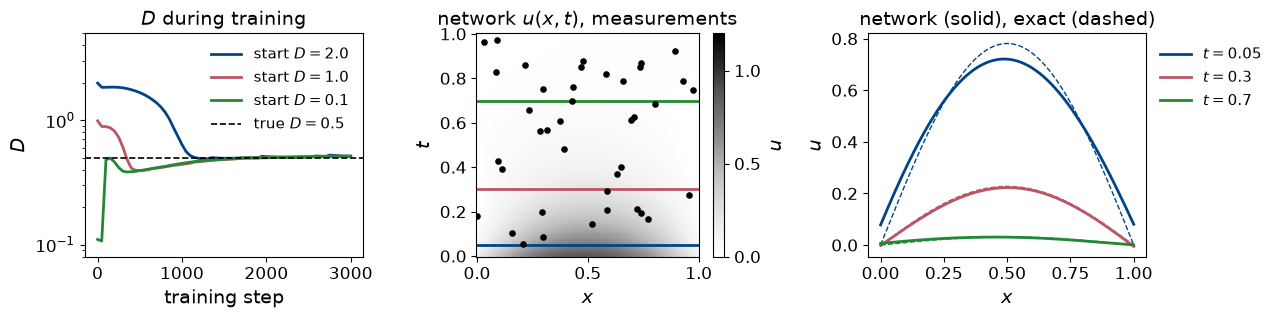

In [19]:
D_TRUE = 0.5


def measurements(n_obs=40, noise=0.01, seed=3):
    rng = np.random.default_rng(seed)
    X_obs = np.column_stack([rng.uniform(0, 1, n_obs), rng.uniform(0, 1, n_obs)])
    y_obs = exact_diffusion(X_obs[:, 0], X_obs[:, 1], D_TRUE) + rng.normal(0, noise, n_obs)
    return jnp.asarray(X_obs), jnp.asarray(y_obs)


def find_D(X_obs, y_obs, D0=2.0, n_iter=3000, lam=10.0):
    params = (to_jax(create_layers([2, 30, 30, 1], "tanh", np.random.default_rng(1))), jnp.array(D0))

    def cost_fn(params):
        layers, D = params
        return (jnp.mean((u_t(layers, X_int) - D * u_xx(layers, X_int)) ** 2)
                + lam * jnp.mean((u_net(layers, X_obs) - y_obs) ** 2))

    return adam_minimise(cost_fn, params, n_iter=n_iter, gamma=1e-2, trace_fn=lambda p: p[1])


t0 = time.time()
X_obs, y_obs = measurements()
runs = []
for D0 in (2.0, 1.0, 0.1):
    params, trace = find_D(X_obs, y_obs, D0=D0)
    runs.append((D0, params, trace))
    print(f"start D = {D0}:  recovered D = {float(params[1]):.4f}")
params5, _ = find_D(*measurements(noise=0.05))
print(f"five times more noise:  recovered D = {float(params5[1]):.4f}  ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for (D0, params, trace), col in zip(runs, (BLUE, RED, GREEN)):
    ax[0].plot(trace[:, 0], trace[:, 2], color=col, lw=2, label=f"start $D={D0}$")
ax[0].axhline(D_TRUE, color="k", lw=1.2, ls="--", label="true $D=0.5$")
ax[0].set_xlabel("training step")
ax[0].set_ylabel("$D$")
ax[0].set_yscale("log")
ax[0].set_ylim(0.08, 5)
ax[0].set_title("$D$ during training")
ax[0].legend(frameon=False, fontsize=11, loc="upper right")
layers_inv = runs[0][1][0]
x = np.linspace(0, 1, 200)
Xg, Tg = np.meshgrid(x, x)
U = np.asarray(u_net(layers_inv, jnp.asarray(np.column_stack([Xg.ravel(), Tg.ravel()])))).reshape(Xg.shape)
im = ax[1].pcolormesh(Xg, Tg, U, cmap="Greys", vmin=0, vmax=1.2, shading="auto")
fig.colorbar(im, ax=ax[1], label="$u$", ticks=[0, 0.5, 1])
ax[1].scatter(np.asarray(X_obs)[:, 0], np.asarray(X_obs)[:, 1], color="k", s=14, zorder=3)
ax[1].set_xlabel("$x$")
ax[1].set_ylabel("$t$")
ax[1].set_title("network $u(x,t)$, measurements")
for ts, col in zip((0.05, 0.3, 0.7), (BLUE, RED, GREEN)):
    ax[1].axhline(ts, color=col, lw=2)
    ax[2].plot(x, np.asarray(u_net(layers_inv, jnp.asarray(np.column_stack([x, np.full_like(x, ts)])))),
               color=col, lw=2, label=f"$t={ts}$")
    ax[2].plot(x, exact_diffusion(x, ts, D_TRUE), color=col, lw=1, ls="--")
ax[2].set_xlabel("$x$")
ax[2].set_ylabel("$u$")
ax[2].set_title("network (solid), exact (dashed)")
ax[2].legend(frameon=False, fontsize=11, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
show(fig, "pinn_inverse.png")

All three starting guesses end close to the true value. But with five times more noise the recovered $D$ is far off: inverse problems are sensitive to noise, so a recovered parameter needs an error bar (for example, from the bootstrap).

## Summary

- **Backpropagation** is the chain rule: compute the errors $\delta^l$ from the output backwards. Always check your gradient against `jax.grad`.
- **Activation functions** must be non-linear, and training only sees $f'$. **Initialise** randomly (all zeros: the network is stuck), with variance $1/M$ (tanh) or $2/M$ (ReLU).
- **Output activation and cost come in pairs**, and then $\delta^L = a - y$.
- **Universal approximation:** a wide enough network can represent any continuous function (a ReLU network does it with kinks), but the theorem says nothing about how many units are needed or whether training finds the weights.
- **Differential equations:** the residual is the cost. Conditions go into the trial solution (hard) or the cost (soft). Use smooth activations. The method is flexible, but slower than standard methods, and without their guarantees.